# MatchWise: Research & Baseline Analysis

**Project:** Decision-Aware Clarification for Sequential Reciprocal Matching  
**Purpose:** Reproducibly inspect the supplied simulator's baseline results before implementing the proposed MatchWise policy.

This notebook:
1. Loads the existing JSON evaluation outputs for `greedy`, `no_asks`, and `random`.
2. Checks that the files contain the expected scenario coverage.
3. Builds overall and scenario-level comparison tables.
4. Visualizes primary score, coverage, mutual acceptances, and clarification cost.
5. Records limitations and the next experiments needed.

> **Research integrity:** These are results from the supplied baseline policies, not results from the proposed MatchWise method. Do not interpret small differences from a small number of seeds as statistically significant. Keep the raw JSON files alongside this notebook for reproducibility.


## 1. Load the experiment outputs

Upload the three **full baseline result JSONs** generated for the same seeds and all six scenarios:
- `greedy.json`
- `no_asks.json`
- `random.json`

Use the versions containing **18 episodes each** (3 seeds × 6 scenario variants), not a single-seed/6-episode run. If these files are already in `/content/results/`, the notebook will use them automatically.


In [2]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

RESULT_DIR = Path("/content/results")
EXPECTED = ["greedy.json", "no_asks.json", "random.json"]

def locate_result(filename):
    candidates = [
        RESULT_DIR / filename,
        Path("/content") / filename,
        Path(filename),
    ]
    for path in candidates:
        if path.exists():
            return path
    return None

missing = [name for name in EXPECTED if locate_result(name) is None]
if missing:
    from google.colab import files
    print("Upload the full 18-episode JSON files. Keep the filenames exactly as shown.")
    uploaded = files.upload()
    print("Uploaded:", list(uploaded.keys()))

paths = {name: locate_result(name) for name in EXPECTED}
missing = [name for name, path in paths.items() if path is None]
if missing:
    raise FileNotFoundError(
        f"Missing {missing}. Upload the files or place them in /content/results/."
    )

results = {}
for name, path in paths.items():
    with open(path, "r", encoding="utf-8") as f:
        results[name.removesuffix(".json")] = json.load(f)
    print(f"{name}: {len(results[name.removesuffix('.json')].get('episodes', []))} episodes — {path}")


greedy.json: 18 episodes — /content/results/greedy.json
no_asks.json: 18 episodes — /content/results/no_asks.json
random.json: 18 episodes — /content/results/random.json


In [3]:
# Validate the basic structure and scenario coverage.
expected_scenarios = {"development", "sparse", "cold_start", "delayed", "shift", "drift"}
validation_rows = []

for policy, payload in results.items():
    episodes = payload.get("episodes", [])
    scenarios = set()
    for episode in episodes:
        scenario = episode.get("scenario") or episode.get("variant")
        if scenario:
            scenarios.add(scenario)
    summary_scenarios = set(payload.get("summary", {}).get("scenario_means", {}).keys())
    if not scenarios:
        scenarios = summary_scenarios

    validation_rows.append({
        "policy": policy,
        "episode_count": len(episodes),
        "scenario_count": len(scenarios),
        "scenarios_found": ", ".join(sorted(scenarios)),
        "has_all_six_scenarios": expected_scenarios.issubset(scenarios),
        "primary_score": payload.get("summary", {}).get("primary_score"),
    })

validation = pd.DataFrame(validation_rows)
display(validation)

if any(len(results[p].get("episodes", [])) != 18 for p in results):
    print("NOTE: At least one file does not contain 18 episodes. Check that you uploaded the full 3-seed × 6-scenario runs.")


,policy,episode_count,scenario_count,scenarios_found,has_all_six_scenarios,primary_score
0,greedy,18,6,"cold_start, delayed, development, drift, shift...",True,0.388889
1,no_asks,18,6,"cold_start, delayed, development, drift, shift...",True,0.138889
2,random,18,6,"cold_start, delayed, development, drift, shift...",True,0.277778


## 2. Overall baseline comparison

The evaluator's primary score is the equally weighted mean of the six scenario-family MSMI outcomes. Higher is better. The remaining metrics are useful diagnostics and tie-breakers; they should not be treated as substitutes for the primary metric.


In [4]:
metric_labels = {
    "msmi_per_100_arrived_members": "MSMI per 100 arrived members (primary score)",
    "coverage": "Coverage",
    "mutual_acceptances_per_100": "Mutual acceptances per 100",
    "ask_cost": "Clarification cost",
    "inference_seconds": "Inference seconds",
}

overall_rows = []
for policy, payload in results.items():
    overall = payload.get("summary", {}).get("overall", {})
    row = {"policy": policy, "primary_score": payload.get("summary", {}).get("primary_score")}
    row.update(overall)
    overall_rows.append(row)

overall_df = pd.DataFrame(overall_rows).set_index("policy")
display(overall_df.round(4))


,primary_score,msmi_per_100_arrived_members,coverage,mutual_acceptances_per_100,ask_cost,inference_seconds
policy,,,,,,
greedy,0.3889,0.3889,0.3717,5.5000,206.6667,25.8981
no_asks,0.1389,0.1389,0.1428,1.7500,0.0000,26.5188
random,0.2778,0.2778,0.3767,5.3333,206.6667,25.4181


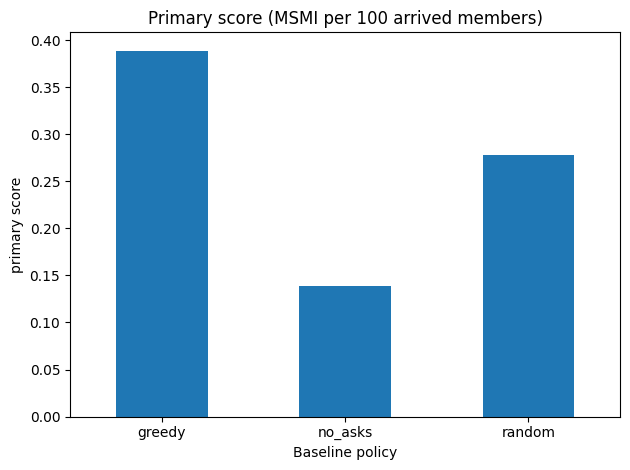

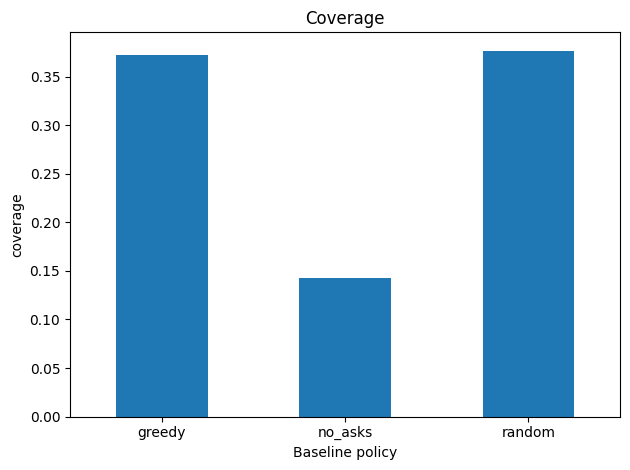

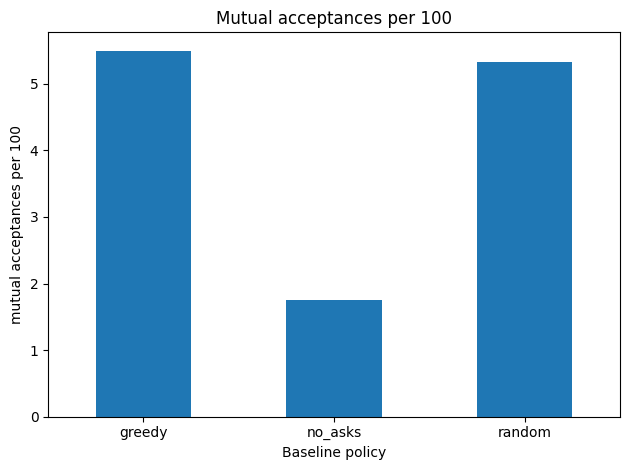

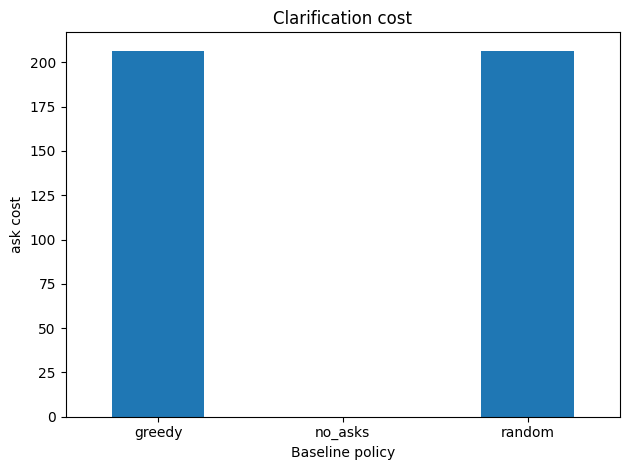

In [5]:
# Plot the main comparison metrics in separate charts for readability.
plot_metrics = [
    ("primary_score", "Primary score (MSMI per 100 arrived members)"),
    ("coverage", "Coverage"),
    ("mutual_acceptances_per_100", "Mutual acceptances per 100"),
    ("ask_cost", "Clarification cost"),
]

for metric, title in plot_metrics:
    if metric in overall_df.columns:
        ax = overall_df[metric].plot(kind="bar", rot=0)
        ax.set_title(title)
        ax.set_xlabel("Baseline policy")
        ax.set_ylabel(metric.replace("_", " "))
        plt.tight_layout()
        plt.show()


## 3. Scenario-level comparison

Scenario averages help reveal where a policy is brittle—for example, under sparse eligibility, cold-start information, or delayed feedback. The supplied evaluator reports scenario means, which we use here directly.


In [6]:
scenario_rows = []
for policy, payload in results.items():
    scenario_means = payload.get("summary", {}).get("scenario_means", {})
    for scenario, metrics in scenario_means.items():
        scenario_rows.append({"policy": policy, "scenario": scenario, **metrics})

scenario_df = pd.DataFrame(scenario_rows)
display(
    scenario_df.pivot(index="scenario", columns="policy", values="msmi_per_100_arrived_members")
    .reindex(sorted(scenario_df["scenario"].unique()))
    .round(4)
)


policy,greedy,no_asks,random
scenario,,,
cold_start,0.1667,0.0000,0.1667
delayed,0.5000,0.3333,0.1667
development,0.5000,0.1667,0.3333
drift,0.5000,0.1667,0.3333
shift,0.5000,0.1667,0.5000
sparse,0.1667,0.0000,0.1667


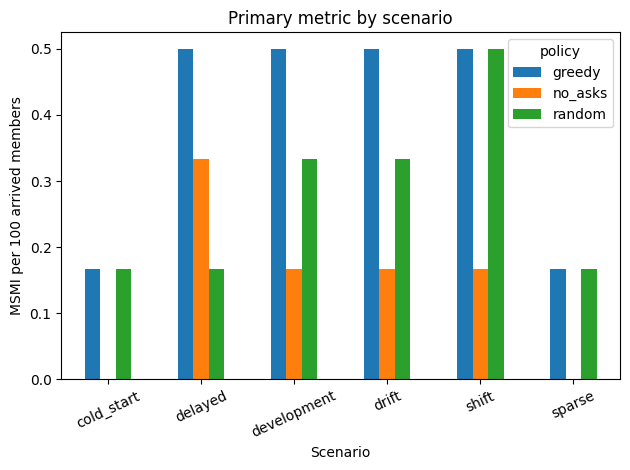

In [7]:
scenario_pivot = scenario_df.pivot(
    index="scenario",
    columns="policy",
    values="msmi_per_100_arrived_members"
)
ax = scenario_pivot.plot(kind="bar", rot=25)
ax.set_title("Primary metric by scenario")
ax.set_xlabel("Scenario")
ax.set_ylabel("MSMI per 100 arrived members")
plt.tight_layout()
plt.show()


## 4. Preliminary interpretation

Use the generated tables and plots to write observations grounded in these runs. Avoid treating these patterns as universal conclusions.

Questions to investigate:
- Does clarification appear useful compared with the `no_asks` baseline?
- How much does performance vary by scenario?
- Does higher coverage necessarily translate into higher MSMI?
- What is the clarification-cost trade-off?
- Which scenario should be prioritized for robustness testing?

**Do not claim that MatchWise outperforms these baselines yet.** This notebook compares only the supplied baseline policies. The proposed decision-aware clarification and global-matching policy must be implemented and evaluated before making such a claim.


In [8]:
# Export clean comparison tables so they can be committed as supporting evidence.
OUT = Path("/content/matchwise_analysis_outputs")
OUT.mkdir(exist_ok=True)

overall_df.to_csv(OUT / "baseline_overall_comparison.csv")
scenario_df.to_csv(OUT / "baseline_scenario_comparison.csv", index=False)
validation.to_csv(OUT / "input_validation.csv", index=False)

print("Saved:")
for p in sorted(OUT.iterdir()):
    print("-", p.name)


Saved:
- baseline_overall_comparison.csv
- baseline_scenario_comparison.csv
- input_validation.csv


## 5. Reproducibility and limitations

- **Inputs:** JSON outputs produced by the provided evaluation harness.
- **Policies compared:** `greedy`, `no_asks`, and `random`.
- **Scenario families:** development, sparse, cold-start, delayed feedback, shift, and drift.
- **Primary metric:** equally weighted scenario-family MSMI per 100 arrived members.
- **Limitations:** simulator-based evaluation; a limited seed set; stochastic outcomes; and baseline-only results. This analysis does not establish real-world relationship compatibility or causal effects.
- **Next step:** implement the proposed policy behind the official policy interface, run it on the same seeds and scenarios, and compare it with these baselines. Include ablations for global matching and selective clarification.
